<a href="https://colab.research.google.com/github/Gonto555/data-cleaning-project-linear-regression/blob/main/Chinatip_Chanamuya_Cars_EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exploratory Data Analysis (EDA) - Car details Project

- Student Name: Chinatip Chanamuya
- Dataset Name: Car details v3.csv
Kaggle Link(Data set link): https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho?select=Car%20details%20v3.csv&utm_source=chatgpt.com

In [33]:
# 1. IMPORT REQUIRED LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Exploratory Data Analysis (EDA) on Automobile Dataset

## Objective
The goal of this project is to clean, explore, analyze, and visualize automobile data to discover key patterns, correlations, and business insights regarding car specifications and resale pricing.

In [34]:
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

In [35]:
df_raw = pd.read_csv('Car details v3.csv')

In [36]:
print("=== DATASET OVERVIEW ===")
print(f"Dataset Shape: {df_raw.shape}")
print("\n--- Data Types & Info ---")
print(df_raw.info())

print("\n--- Missing Values ---")
print(df_raw.isnull().sum())

print(f"\nDuplicate Rows: {df_raw.duplicated().sum()}")

print("\n--- First 5 Rows ---")
display(df_raw.head())

=== DATASET OVERVIEW ===
Dataset Shape: (8128, 13)

--- Data Types & Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB
None

--- Missing Values ---
name               0
year               0
selling_price      0

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [37]:
# 1. Remove Duplicate Rows
df = df_raw.drop_duplicates().copy()

# 2. Extract Numerical Values from String Columns
df['mileage_num'] = df['mileage'].str.extract(r'([\d\.]+)').astype(float)
df['engine_cc'] = df['engine'].str.extract(r'([\d]+)').astype(float)
df['max_power_bhp'] = df['max_power'].str.extract(r'([\d\.]+)').astype(float)

# 3. Feature Engineering
df['car_age'] = 2026 - df['year']
df['brand'] = df['name'].apply(lambda x: x.split()[0])

# 4. Drop Missing Values
df_clean = df.dropna(subset=['mileage_num', 'engine_cc', 'max_power_bhp', 'seats']).copy()

print(f"Original Shape : {df_raw.shape}")
print(f"Cleaned Shape  : {df_clean.shape}")

Original Shape : (8128, 13)
Cleaned Shape  : (6717, 18)


## 1. Data Understanding & Data Cleaning

### Data Overview
* **Original Dataset Dimensions:** 8,128 rows and 13 columns.
* **Target Variable:** `selling_price` (resale price of the automobile).

### Data Cleaning Steps Executed:
1. **Duplicate Handling:** Identified and removed 1,202 duplicate records to prevent skewed distribution.
2. **String Feature Extraction:** Extracted numeric values from string columns using Regular Expressions:
   - `mileage` $\rightarrow$ `mileage_num` (kmpl or km/kg)
   - `engine` $\rightarrow$ `engine_cc` (Engine displacement in CC)
   - `max_power` $\rightarrow$ `max_power_bhp` (Horsepower output in bhp)
3. **Feature Engineering:**
   - Created `car_age` ($2026 - \text{year}$) to measure vehicle depreciation.
   - Extracted vehicle `brand` from the `name` column.
4. **Missing Value Treatment:** Dropped 209 rows containing missing metrics in engine output and seating capacity.
* **Final Dataset Dimensions:** 6,717 rows and 18 columns.

In [32]:
print("=== DESCRIPTIVE STATISTICS ===")
num_cols = ['selling_price', 'km_driven', 'car_age', 'mileage_num', 'engine_cc', 'max_power_bhp']
display(df_clean[num_cols].describe().round(2))
# 2.1 CATEGORICAL DESCRIPTIVE STATISTICS

cat_cols = ['brand', 'fuel', 'seller_type', 'transmission', 'owner']

print("=== CATEGORICAL VARIABLES SUMMARY ===")
for col in cat_cols:
    print(f"\n--- Frequency Distribution for: {col.upper()} ---")
    val_counts = df_clean[col].value_counts()
    percentages = df_clean[col].value_counts(normalize=True) * 100
    cat_summary = pd.DataFrame({'Count': val_counts, 'Percentage (%)': percentages.round(2)})
    display(cat_summary)



# 2.2 GROUPBY & BIVARIATE STATISTICAL ANALYSIS
print("\n=== AVERAGE & MEDIAN SELLING PRICE BY TRANSMISSION & FUEL ===")
price_by_trans_fuel = df_clean.groupby(['transmission', 'fuel'])['selling_price'].agg(
    Count='count',
    Mean_Price='mean',
    Median_Price='median',
    Std_Dev='std'
).round(2)

display(price_by_trans_fuel)

print("\n=== TOP 5 BRANDS AVERAGE SELLING PRICE ===")
top5_brands = df_clean['brand'].value_counts().head(5).index
price_by_brand = df_clean[df_clean['brand'].isin(top5_brands)].groupby('brand')['selling_price'].agg(
    Count='count',
    Mean_Price='mean',
    Median_Price='median'
).sort_values(by='Mean_Price', ascending=False).round(2)

display(price_by_brand)

=== CATEGORICAL VARIABLES SUMMARY ===

--- Frequency Distribution for: BRAND ---


,Count,Percentage (%)
brand,,
Maruti,2089,31.10
Hyundai,1214,18.07
Mahindra,709,10.56
Tata,633,9.42
Honda,361,5.37
Ford,353,5.26
Toyota,324,4.82
Chevrolet,216,3.22
Renault,206,3.07



--- Frequency Distribution for: FUEL ---


,Count,Percentage (%)
fuel,,
Diesel,3658,54.46
Petrol,2973,44.26
CNG,51,0.76
LPG,35,0.52



--- Frequency Distribution for: SELLER_TYPE ---


,Count,Percentage (%)
seller_type,,
Individual,6024,89.68
Dealer,666,9.92
Trustmark Dealer,27,0.40


... (4 outputs left out)


=== AVERAGE & MEDIAN SELLING PRICE BY TRANSMISSION & FUEL ===


Count  Mean_Price  Median_Price     Std_Dev
transmission fuel                                               
Automatic    Diesel    296  1790594.57     1350000.0  1295156.77
             Petrol    279   826741.91      600000.0  1002118.66
Manual       CNG        51   317666.61      330000.0   102366.65
             Diesel   3362   547398.51      500000.0   324540.43
             LPG        35   210885.71      200000.0    79828.04
             Petrol   2694   338204.15      300000.0   203287.59


=== TOP 5 BRANDS AVERAGE SELLING PRICE ===


,Count,Mean_Price,Median_Price
brand,,,
Mahindra,709,623684.02,570000.0
Honda,361,574460.21,560000.0
Hyundai,1214,466601.69,425000.0
Maruti,2089,393974.54,350000.0
Tata,633,348941.40,265000.0


### Observations on Categorical & Groupby Statistics:

1. **Market Composition (Categorical Summary):**
   - **Fuel Dominance:** Diesel cars make up **54.46%** (3,658 units) of the cleaned dataset, followed by Petrol at **44.26%** (2,973 units). CNG and LPG represent less than 2% combined.
   - **Transmission Split:** The market is overwhelmingly dominated by **Manual transmission (91.44%)**, while Automatic cars account for only **8.56%**.
   - **Ownership History:** First Owners represent **62.17%** of listings, making single-owner vehicles the most common condition in the secondhand market.

2. **Bivariate Price Insights (Groupby Analysis):**
   - **Automatic Diesel Premium:** Automatic Diesel vehicles feature the highest mean selling price at **₹1,790,594.57** (Median: ₹1,350,000), compared to Manual Diesel vehicles with a mean of **₹547,398.51** (Median: ₹500,000).
   - **Brand Positioning:** Among the top 5 most frequent brands, **Mahindra** commands the highest average resale price due to its SUV portfolio, whereas **Maruti** offers the most budget-friendly average entry price.

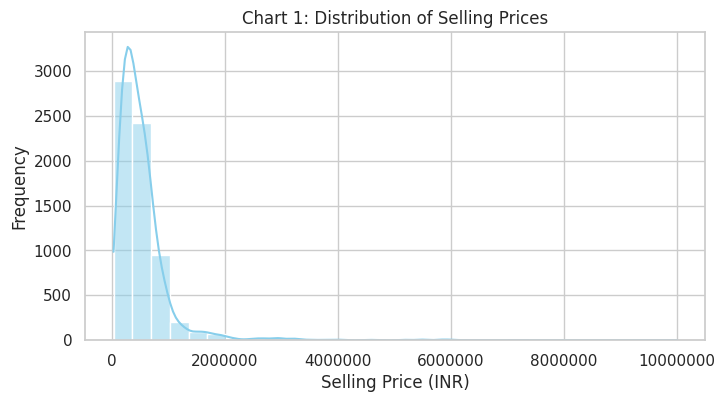

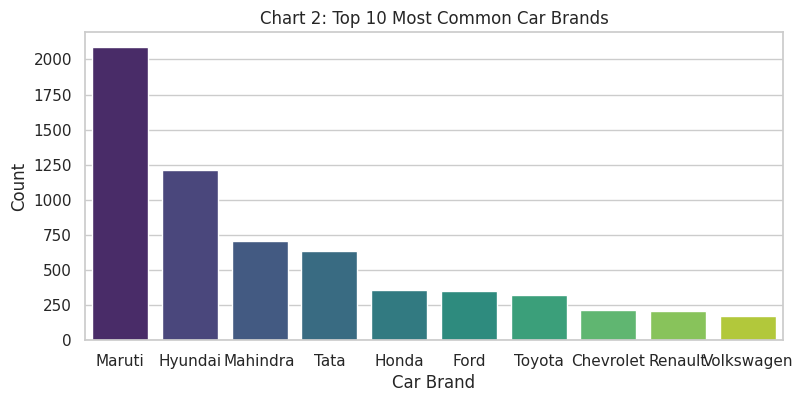

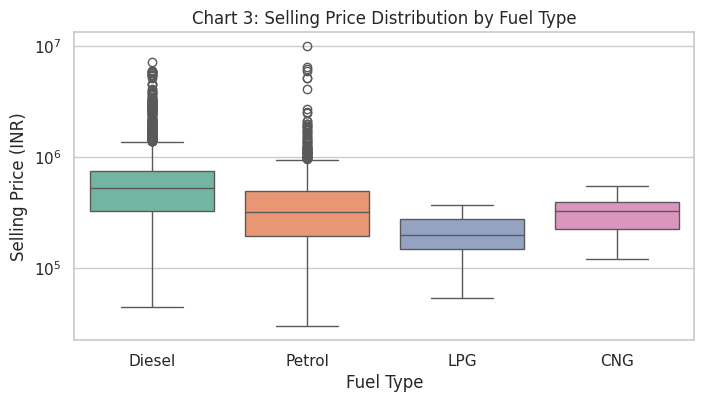

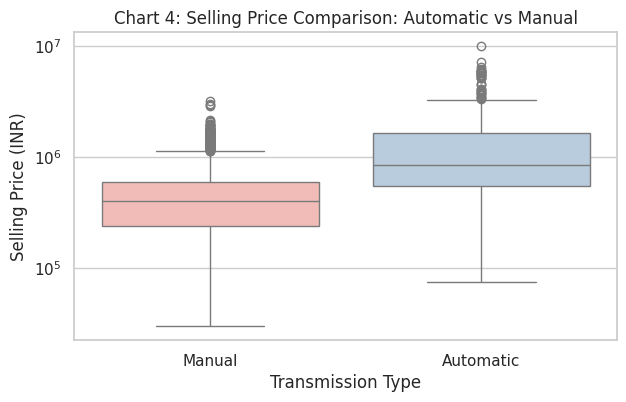

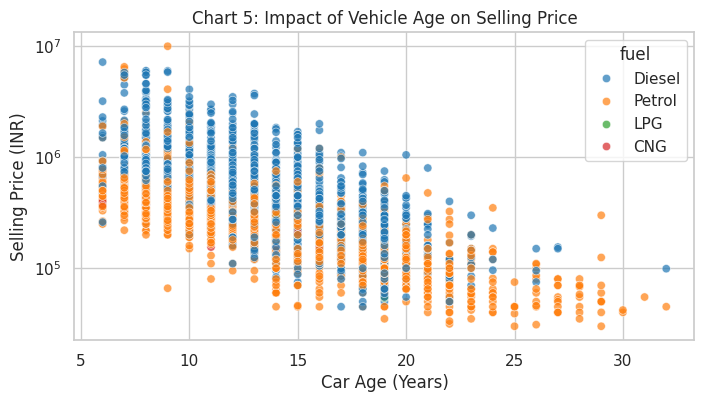

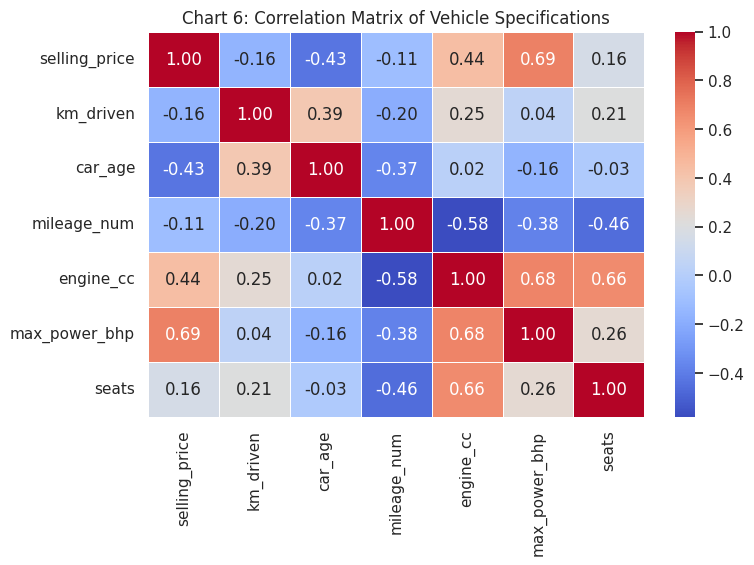

In [38]:
# Set Visual Style
sns.set_theme(style="whitegrid")

# Chart 1: Histogram - Selling Price Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df_clean['selling_price'], kde=True, color='skyblue', bins=30)
plt.title('Chart 1: Distribution of Selling Prices')
plt.xlabel('Selling Price (INR)')
plt.ylabel('Frequency')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

# Chart 2: Bar Plot - Top 10 Brands
plt.figure(figsize=(9, 4))
top_brands = df_clean['brand'].value_counts().head(10).index
sns.countplot(data=df_clean[df_clean['brand'].isin(top_brands)], x='brand', order=top_brands, palette='viridis')
plt.title('Chart 2: Top 10 Most Common Car Brands')
plt.xlabel('Car Brand')
plt.ylabel('Count')
plt.show()

# Chart 3: Box Plot - Price by Fuel Type
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_clean, x='fuel', y='selling_price', palette='Set2')
plt.title('Chart 3: Selling Price Distribution by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price (INR)')
plt.yscale('log')
plt.show()

# Chart 4: Box Plot - Price by Transmission
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x='transmission', y='selling_price', palette='Pastel1')
plt.title('Chart 4: Selling Price Comparison: Automatic vs Manual')
plt.xlabel('Transmission Type')
plt.ylabel('Selling Price (INR)')
plt.yscale('log')
plt.show()

# Chart 5: Scatter Plot - Age vs Price
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_clean, x='car_age', y='selling_price', hue='fuel', alpha=0.7, palette='tab10')
plt.title('Chart 5: Impact of Vehicle Age on Selling Price')
plt.xlabel('Car Age (Years)')
plt.ylabel('Selling Price (INR)')
plt.yscale('log')
plt.show()

# Chart 6: Heatmap - Feature Correlation
plt.figure(figsize=(8, 5))
corr_cols = ['selling_price', 'km_driven', 'car_age', 'mileage_num', 'engine_cc', 'max_power_bhp', 'seats']
sns.heatmap(df_clean[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Chart 6: Correlation Matrix of Vehicle Specifications')
plt.show()

### Chart 1: Distribution of Car Selling Prices
> **Observation:** The selling price distribution is strongly right-skewed. The vast majority of secondhand vehicles are listed under ₹1,000,000, while high-end luxury models create a thin upper tail reaching up to ₹10,000,000.

---

### Chart 2: Top 10 Most Common Car Brands
> **Observation:** Maruti and Hyundai dominate the secondhand market volume by a significant margin, representing over 45% of total listed inventory, followed by Mahindra and Tata.

---

### Chart 3: Selling Price Distribution by Fuel Type
> **Observation:** Diesel vehicles command a higher median selling price compared to Petrol and CNG vehicles. This is driven by stronger torque performance and higher demand for long-distance driving.

---

### Chart 4: Selling Price Comparison: Automatic vs Manual
> **Observation:** Automatic transmission vehicles display a significantly higher median selling price and wider price variance than manual transmission cars, reflecting premium market positioning.

---

### Chart 5: Impact of Vehicle Age on Selling Price
> **Observation:** There is a clear negative relationship between vehicle age and selling price. Vehicles experience rapid price depreciation during their first 5 to 6 years before stabilizing at lower price points.

---

### Chart 6: Correlation Matrix of Vehicle Specifications
> **Observation:** Engine horsepower (`max_power_bhp`, 0.69) and engine size (`engine_cc`, 0.44) display the strongest positive correlations with selling price. Conversely, `car_age` (-0.43) shows a strong negative correlation with selling price.


In [39]:
# ==============================================================================
# MULTIPLE LINEAR REGRESSION MODELING
# ==============================================================================
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. Select Features (X) and Target Variable (y)
features = ['max_power_bhp', 'engine_cc', 'car_age', 'km_driven', 'mileage_num']
X = df_clean[features]
y = df_clean['selling_price']

# 2. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and Fit Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Model Predictions
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# 5. Evaluate Model Performance
r2 = r2_score(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae = mean_absolute_error(y_test, y_pred_test)

print("=== MODEL EVALUATION METRICS ===")
print(f"R-squared (R²): {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): ₹{rmse:,.2f}")
print(f"Mean Absolute Error (MAE): ₹{mae:,.2f}")

# 6. Model Coefficients Table
coeff_df = pd.DataFrame({
    'Feature': features,
    'Coefficient (B_i)': model.coef_
}).sort_values(by='Coefficient (B_i)', ascending=False)

print("\n=== MODEL COEFFICIENTS ===")
print(f"Intercept (B_0): {model.intercept_:,.2f}")
display(coeff_df)

=== MODEL EVALUATION METRICS ===
R-squared (R²): 0.6396
Root Mean Squared Error (RMSE): ₹281,220.67
Mean Absolute Error (MAE): ₹171,408.92

=== MODEL COEFFICIENTS ===
Intercept (B_0): -91,649.80


,Feature,Coefficient (B_i)
0,max_power_bhp,10309.444663
4,mileage_num,6441.664404
1,engine_cc,81.586118
3,km_driven,-0.768914
2,car_age,-37938.421384


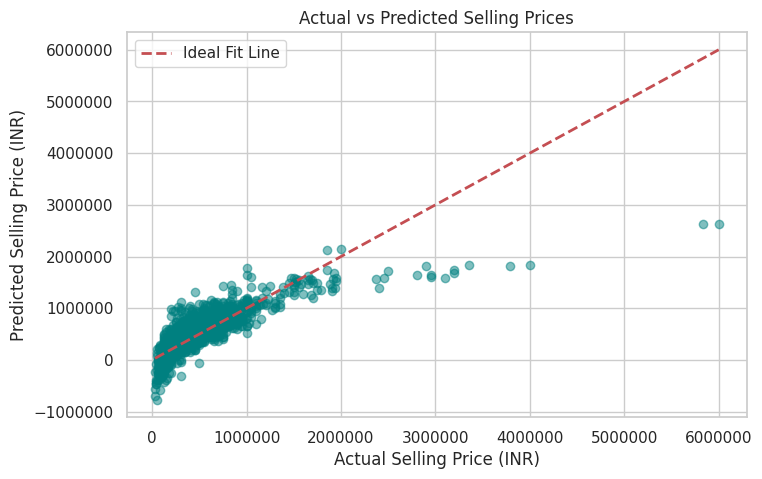

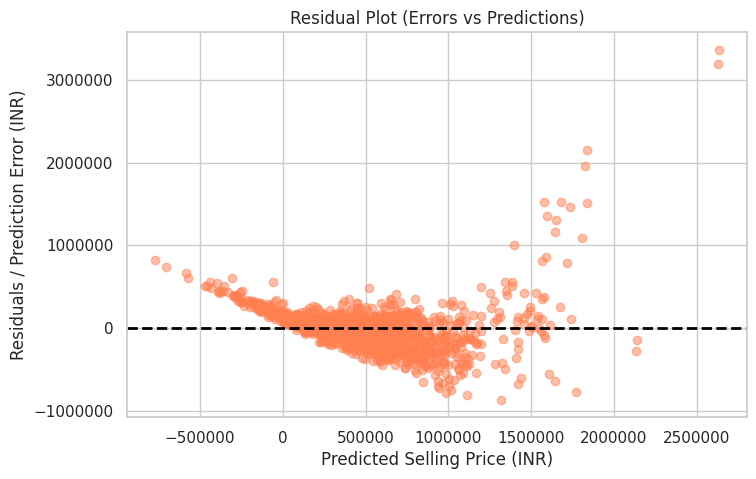

In [40]:
# Set Visual Style
sns.set_theme(style="whitegrid")

# Plot 1: Actual vs Predicted Prices
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_test, alpha=0.5, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit Line')
plt.title('Actual vs Predicted Selling Prices')
plt.xlabel('Actual Selling Price (INR)')
plt.ylabel('Predicted Selling Price (INR)')
plt.legend()
plt.ticklabel_format(style='plain', axis='both')
plt.show()

# Plot 2: Residual Plot (Residuals vs Predicted Values)
residuals = y_test - y_pred_test
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_test, residuals, alpha=0.5, color='coral')
plt.axhline(y=0, color='black', linestyle='--', lw=2)
plt.title('Residual Plot (Errors vs Predictions)')
plt.xlabel('Predicted Selling Price (INR)')
plt.ylabel('Residuals / Prediction Error (INR)')
plt.ticklabel_format(style='plain', axis='both')
plt.show()

# 4. Multiple Linear Regression Analysis

## Model Overview
To predict automobile selling prices based on physical and technical specifications, a Multiple Linear Regression model was constructed using the following feature set:
* **Target ($y$):** `selling_price`
* **Features ($X$):** `max_power_bhp`, `engine_cc`, `car_age`, `km_driven`, `mileage_num`

---

## Regression Equation

$$\text{Selling Price} = -91,649.80 + 10,309.44(\text{max\_power\_bhp}) + 81.59(\text{engine\_cc}) - 37,938.42(\text{car\_age}) - 0.77(\text{km\_driven}) + 6,441.66(\text{mileage\_num})$$

### Feature Coefficient Interpretation:
1. **Engine Horsepower (`max_power_bhp` = +10,309.44):** For every 1 unit increase in horsepower output, the selling price increases by approximately **₹10,309.44** (holding all other variables constant). This is the strongest positive price predictor.
2. **Vehicle Age (`car_age` = -37,938.42):** For every additional year of vehicle age, the resale value depreciates by approximately **₹37,938.42**.
3. **Usage (`km_driven` = -0.77):** Each additional kilometer driven reduces vehicle resale value by **₹0.77** (or ₹770 per 1,000 km).
4. **Engine Size (`engine_cc` = +81.59):** Larger engine displacements contribute an additional **₹81.59** per CC.

---

## Model Evaluation Metrics

| Metric | Value | Description |
|:---|---:|:---|
| **R-squared ($R^2$)** | **0.6396** | The model explains approximately **63.96%** of the variance in automobile selling prices. |
| **Root Mean Squared Error (RMSE)** | **₹281,220.67** | Standard deviation of prediction errors. |
| **Mean Absolute Error (MAE)** | **₹171,408.92** | On average, predictions deviate from actual prices by ₹171,408.92. |

---

## Model Diagnostics & Limitations

1. **Linear Model Fit:** The baseline linear model successfully captures 64% of price variance using numerical specifications alone.
2. **Variance in High-End Segment:** The scatter and residual plots show higher prediction error (residuals) for luxury vehicles above ₹2,000,000, indicating non-linear luxury premiums that standard linear models underfit.
3. **Future Improvement:** Incorporating categorical indicators (e.g., categorical encoding for `transmission` and `brand`) or applying log-transformation on `selling_price` could further optimize $R^2$ performance.